id: notebooks/04_observation.ipynb

source tracking, geometric delay and fringe rate, uv-tracks by Earth rotation, visibilities over a track, transit (drift scan) of fixed antennas

<!-- notebooks/04_observation.ipynb -- observation (Interferosim 0.5.1) -->
# 04 – Observation: Earth rotation, uv-coverage, transit

---
  DI Erich Schubert, 07925151
  


Notebook 03 simulated a few seconds of SDR samples. Over hours the Earth's rotation changes the geometry: the source rises and sets, the geometric delay and the fringe rate run through a daily cycle, and the projected baseline traces a **uv-track** – an ellipse in the uv-plane. This *Earth rotation synthesis* is what lets a single baseline sample many spatial frequencies of the sky.

This notebook works with integrated visibilities instead of raw samples (fast enough for hours of observation): `Observation`, `UVCoverage`, `VisibilitySimulator`, `TransitSimulator` (package `interferosim.observation`) and the data class `VisData` (module `interferosim.visdata`).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel, FieldCenter
from interferosim.observation import (Observation, UVCoverage, VisibilitySimulator, TransitSimulator,
                                      sun_radec_deg, mjd_from_iso)
from interferosim.plotting import plot_uv_coverage, plot_elevation, plot_visdata
from interferosim.visdata import VisData

CFG = Path("..") / "configs"
DATE = "2026-11-01"
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")

def baseline_array(b_m, azimuth_deg=90.0, antenna=dish, name=None):
    """Wilhelmsburg plus one station b_m away in the direction azimuth_deg (90 = east)."""
    az = np.radians(azimuth_deg)
    return Array(site, [Station.from_enu("W", site, 0, 0, 0, antenna),
                        Station.from_enu("X", site, b_m * np.sin(az), b_m * np.cos(az), 0, antenna)],
                 receiver=b210, name=name or f"{b_m / 1e3:g} km, azimuth {azimuth_deg:g} deg")

target = baseline_array(11_500.0, 90.0, name="project baseline 11.5 km east-west (model)")
aas6 = Array.from_toml(CFG / "sites" / "aas6_sim_stations.toml")
SKIES = {n: SkyModel.from_json(CFG / "skies" / f"{n}.json") for n in ("cas_a", "cyg_a", "tau_a", "vir_a", "orion_a")}
ra_sun, dec_sun = (float(x) for x in sun_radec_deg(mjd_from_iso(DATE + "T11:00:00")))
sun = SkyModel.from_json(CFG / "skies" / "sun_21cm.json")
sun.center = FieldCenter("Sun", ra_sun, dec_sun)
print(f"Sun on {DATE}: RA {ra_sun:.2f} deg, Dec {dec_sun:+.2f} deg")

Sun on 2026-11-01: RA 216.64 deg, Dec -14.50 deg


## 1. The sources over the day

Elevation of the known sources at Wilhelmsburg over the hour angle (0 h = upper transit). A source is usable above about 10° elevation; northern sources (Cas A, Cyg A) are circumpolar or nearly so, the Sun in November and Orion A stay low.

source         Dec  max el  h above 10 deg   transit (UTC)
cas_a       +58.81    79.3            24.0 19:35
cyg_a       +40.73    82.6            17.0 16:12
tau_a       +22.01    63.9            13.3 01:50
vir_a       +12.39    54.3            11.8 08:45
orion_a      -5.39    36.5             9.1 01:50
sun         -14.50    27.4             7.4 10:40


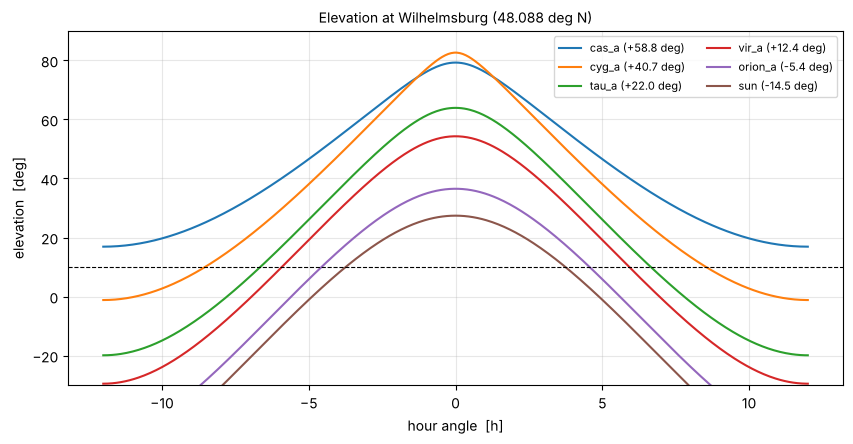

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ha = np.linspace(-12, 12, 481)
print(f"{'source':<10s} {'Dec':>7s} {'max el':>7s} {'h above 10 deg':>15s} {'transit (UTC)':>15s}")
for name, sky in list(SKIES.items()) + [("sun", sun)]:
    obs = Observation.from_sky(sky, target, date=DATE)
    el = obs.elevation_deg(ha * 15)[0]
    ax.plot(ha, el, label=f"{name} ({sky.center.dec_deg:+.1f} deg)")
    up = (el >= 10).mean() * 24
    t = obs.transit_mjd()
    hh = (t % 1) * 24
    print(f"{name:<10s} {sky.center.dec_deg:+7.2f} {el.max():7.1f} {up:15.1f} {int(hh):02d}:{int(hh % 1 * 60):02d}")
ax.axhline(10, color="k", ls="--", lw=0.8)
ax.set_xlabel("hour angle  [h]"); ax.set_ylabel("elevation  [deg]"); ax.set_ylim(-30, 90)
ax.set_title(f"Elevation at Wilhelmsburg ({site.lat_deg:.3f} deg N)", fontsize=10)
ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2); plt.show()

## 2. Geometric delay and fringe rate

On the 11.5 km east–west baseline the delay of Cygnus A runs between about ±29 µs during the day, the natural fringe rate reaches about 3 Hz at transit. The correlator has to follow both (notebook 03, delay tracking and fringe stopping). For an east–west baseline the delay is zero at transit and the fringe rate is largest there.

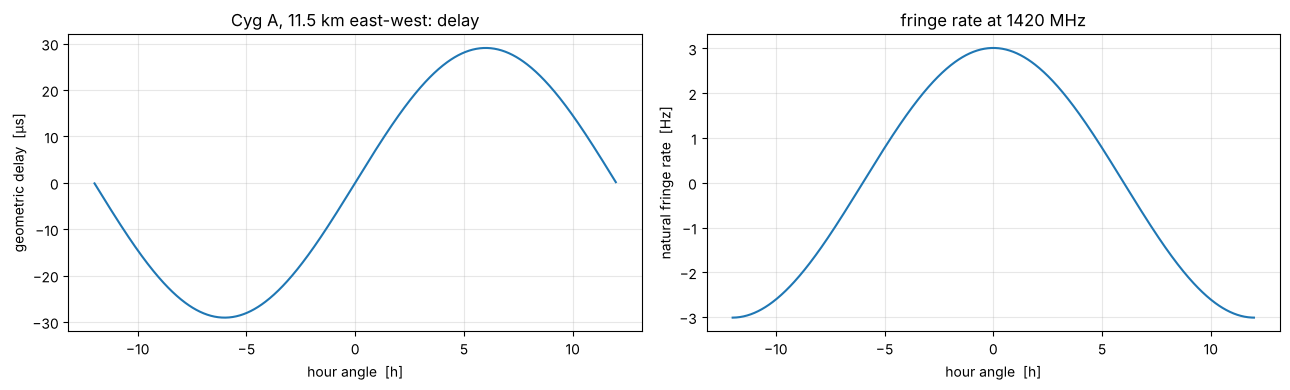

delay range -29.1 ... 29.1 µs, max |fringe rate| 3.01 Hz


In [3]:
obs = Observation.from_sky(SKIES["cyg_a"], target, ha_range_h=(-12, 12), t_int_s=120, date=DATE)
ha = obs.hour_angles() / 15
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ha, obs.delay_s()[0] * 1e6)
axes[0].set_ylabel("geometric delay  [µs]"); axes[0].set_title("Cyg A, 11.5 km east-west: delay")
axes[1].plot(ha, obs.fringe_rate_hz()[0])
axes[1].set_ylabel("natural fringe rate  [Hz]"); axes[1].set_title("fringe rate at 1420 MHz")
for ax in axes:
    ax.set_xlabel("hour angle  [h]"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print(f"delay range {obs.delay_s().min() * 1e6:.1f} ... {obs.delay_s().max() * 1e6:.1f} µs, "
      f"max |fringe rate| {np.abs(obs.fringe_rate_hz()).max():.2f} Hz")

## 3. uv-coverage

An east–west baseline traces an ellipse with the semi-axes $b/\lambda$ (in $u$) and $b\sin\delta/\lambda$ (in $v$): sources near the pole give circles, sources near the equator flat ellipses – poor resolution in north–south direction. Only the part above the elevation limit is usable (coloured; grey: below 10°). Each track has its mirror image ($V(-u,-v) = V^*(u,v)$).

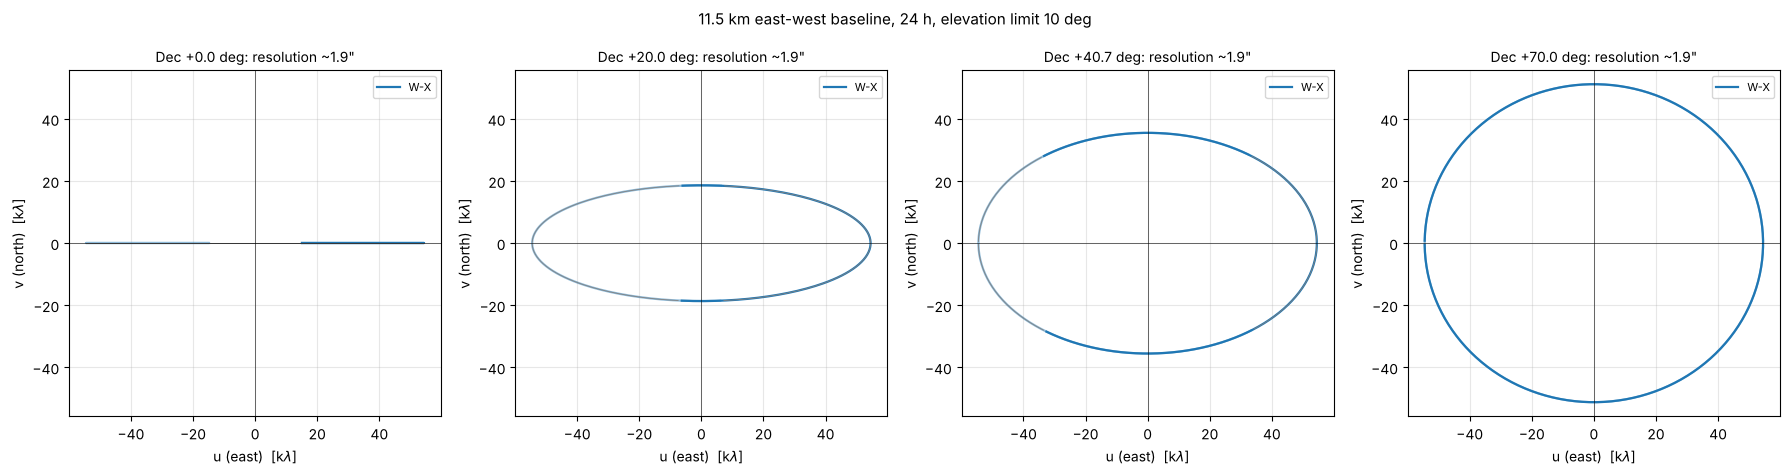

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, dec in zip(axes, (0.0, 20.0, 40.7, 70.0)):
    o = Observation(target, ra_deg=0.0, dec_deg=dec, ha_range_h=(-12, 12), t_int_s=300, date=DATE)
    cov = UVCoverage.from_observation(o)
    plot_uv_coverage(cov, ax=ax, title=f"Dec {dec:+.1f} deg: resolution ~{cov.resolution_arcsec():.2g}\"")
fig.suptitle("11.5 km east-west baseline, 24 h, elevation limit 10 deg", fontsize=11)
fig.tight_layout(); plt.show()

More stations give more baselines and fill the uv-plane faster. As an illustration a hypothetical third station 6 km north of Wilhelmsburg (not a planned site): three baselines with different orientations.

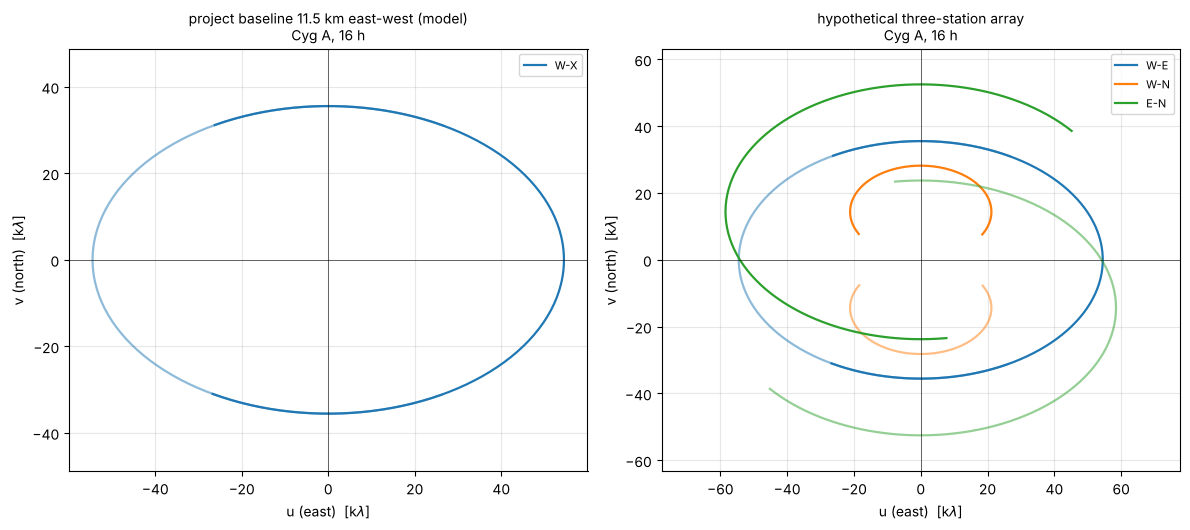

In [5]:
three = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                     Station.from_enu("E", site, 11_500, 0, 0, dish),
                     Station.from_enu("N", site, 0, 6_000, 0, dish)], receiver=b210,
              name="hypothetical three-station array")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, arr in zip(axes, (target, three)):
    o = Observation.from_sky(SKIES["cyg_a"], arr, ha_range_h=(-8, 8), t_int_s=300, date=DATE)
    plot_uv_coverage(UVCoverage.from_observation(o), ax=ax, title=f"{arr.name}\nCyg A, 16 h")
fig.tight_layout(); plt.show()

## 4. Visibilities over a track

Cygnus A on the 11.5 km baseline over ±6 h, one-minute integrations, two 3 m dishes with the B210 (2 MHz): the points are the simulated measurement with radiometer noise, the line the noise-free model. The amplitude oscillates because the projected baseline sweeps across the fringe pattern of the two hotspots (notebook 02); the phase carries their position. This is the raw material for imaging (notebook 06).

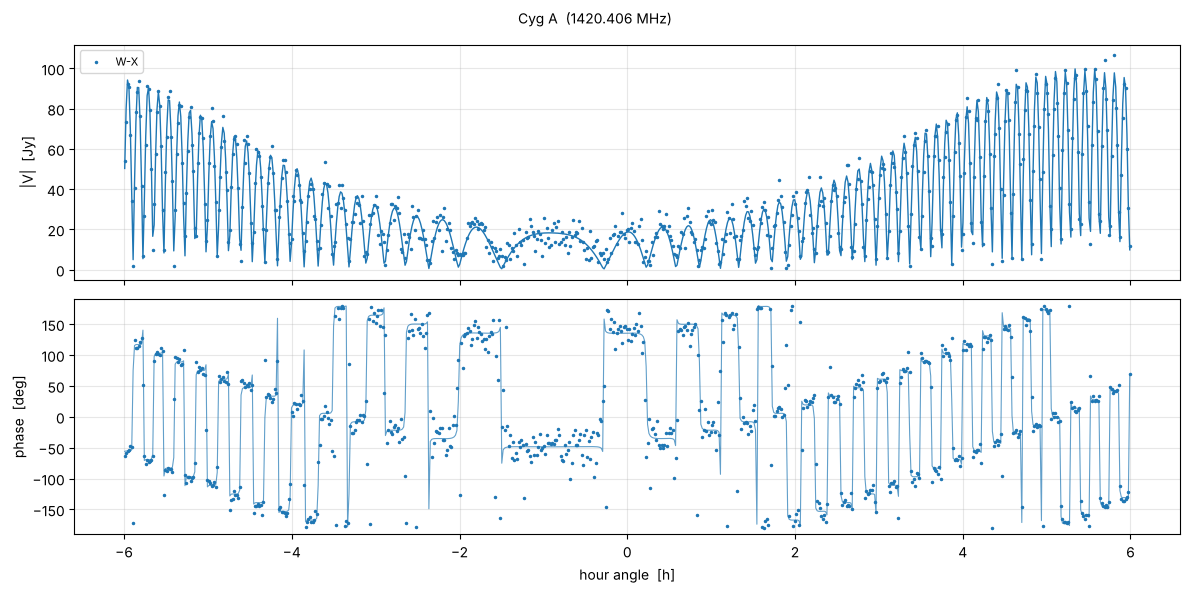

718 integrations, noise sigma 5.14 Jy per minute, |V| model 0.4 ... 99.8 Jy
header: {'OBJECT': 'Cyg A', 'TELESCOP': 'project baseline 11.5 km east-west (model)', 'INSTRUME': 'Ettus USRP B210', 'INTTIME': 60, 'SIMULATD': True}


In [6]:
obs = Observation.from_sky(SKIES["cyg_a"], target, ha_range_h=(-6, 6), t_int_s=60, date=DATE)
vd = VisibilitySimulator(seed=5).run(SKIES["cyg_a"], obs)
model = VisibilitySimulator(add_noise=False).run(SKIES["cyg_a"], obs)
fig, axes = plot_visdata(vd, model=model)
plt.show()
print(f"{vd.n_rows} integrations, noise sigma {vd.sigma[0, 0]:.2f} Jy per minute, "
      f"|V| model {np.abs(model.vis).min():.1f} ... {np.abs(model.vis).max():.1f} Jy")
print("header:", {k: vd.header[k] for k in ("OBJECT", "TELESCOP", "INSTRUME", "INTTIME", "SIMULATD")})

### Why the track is not symmetric about transit

The Earth's rotation moves the baseline symmetrically about transit: for an east–west baseline $u = (b/\lambda)\cos H$ and $v = (b/\lambda)\sin H\sin\delta$, so at $-H$ and $+H$ the coordinate $u$ is the same and $v$ has the opposite sign – the two halves of the track see the sky at $(u, -v)$ and $(u, +v)$, mirrored at the $u$ axis. The amplitudes are only equal for a source that is mirror-symmetric north–south (round, or aligned exactly east–west or north–south). The jet axis of Cygnus A lies at a position angle of about $-70^\circ$ (WNW–ESE); the fringe pattern of the two hotspots depends on $u\,\Delta x + v\,\Delta y$, i.e. on $u\,\Delta x - |v|\,\Delta y$ before and $u\,\Delta x + |v|\,\Delta y$ after transit. The oscillations therefore run at different speeds on the two sides, and the envelope of the elongated lobes differs too. The phase changes sign under the mirror as well ($V(-u,-v) = V^*(u,v)$).

Counter-check: the same source with its axis turned east–west gives an almost symmetric track (the small rest comes from the baseline at 48° latitude not lying exactly perpendicular to the Earth's axis). The asymmetry is not a defect but the information on the orientation of the source – the reason why a source is observed over the whole day (Earth rotation synthesis).

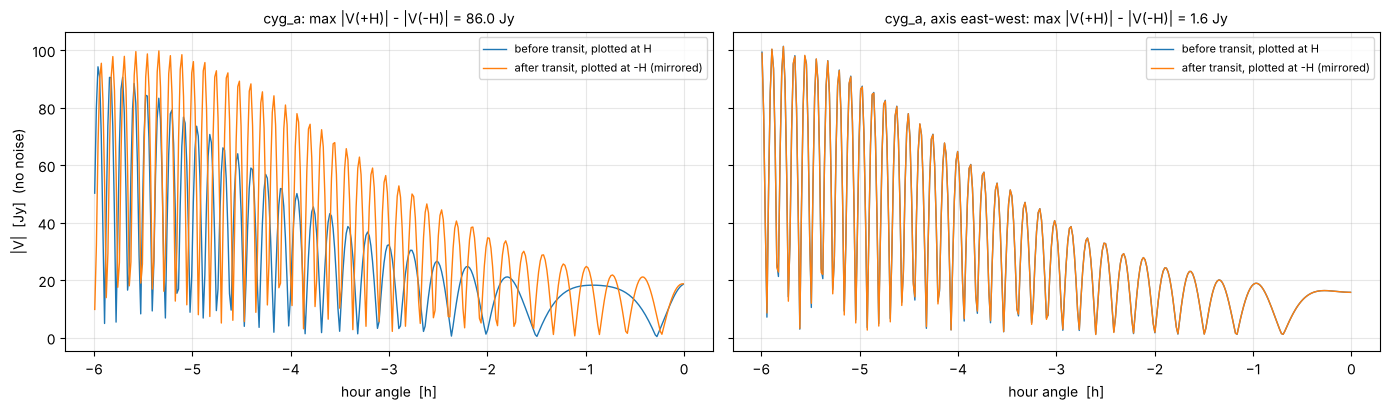

In [7]:
import copy
cyga = SKIES["cyg_a"]
cyga_ew = copy.deepcopy(cyga)                 # same components, jet axis turned east-west
for c in cyga_ew.components:
    c.dx_deg, c.dy_deg = np.sign(c.dx_deg) * np.hypot(c.dx_deg, c.dy_deg), 0.0
    if hasattr(c, "pa_deg"):
        c.pa_deg = 0.0
cyga_ew.name = "cyg_a, axis east-west"

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, s in zip(axes, (cyga, cyga_ew)):
    o = Observation.from_sky(s, target, ha_range_h=(-6, 6), t_int_s=60, date=DATE)
    v = VisibilitySimulator(add_noise=False).run(s, o)
    h, a = v.ha_deg / 15, np.abs(v.vis[:, 0])
    ax.plot(h[h <= 0], a[h <= 0], lw=1, label="before transit, plotted at H")
    ax.plot(-h[h >= 0], a[h >= 0], lw=1, label="after transit, plotted at -H (mirrored)")
    ax.set_xlabel("hour angle  [h]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_title(f"{s.name}: max |V(+H)| - |V(-H)| = {np.max(np.abs(a - a[::-1])):.1f} Jy", fontsize=10)
axes[0].set_ylabel("|V|  [Jy]  (no noise)")
fig.tight_layout(); plt.show()

`VisData` stores one row per integration and baseline (columns as in `aas6sim`: time, hour angle, u, v, w, visibility, weight, plus a baseline index and a frequency axis). It can be saved and loaded; FITS output follows with the package `io`. The output folder `notebooks/sim_output/` is not under version control.

In [8]:
out = Path("sim_output"); out.mkdir(exist_ok=True)
p = vd.save_npz(out / "cyga_11p5km_12h.npz")
back = VisData.load_npz(p)
print(p.name, f"{p.stat().st_size / 1e3:.0f} kB,", back.n_rows, "rows,", back.n_chan, "channel(s), baselines", back.baseline_names)

cyga_11p5km_12h.npz 39 kB, 718 rows, 1 channel(s), baselines ['W-X']


## 5. Transit: fixed antennas, the Sun drifts through the beam

The first experiment of the project (notebook B): two horns 10 m apart on one B210, fixed and pointing at the meridian at the declination of the Sun. The Sun drifts through the horn beams (HPBW 34°) within a few hours; without fringe stopping the correlation shows the fringes under the envelope of the beam. The fringe period follows from the fringe rate of the 10 m baseline.

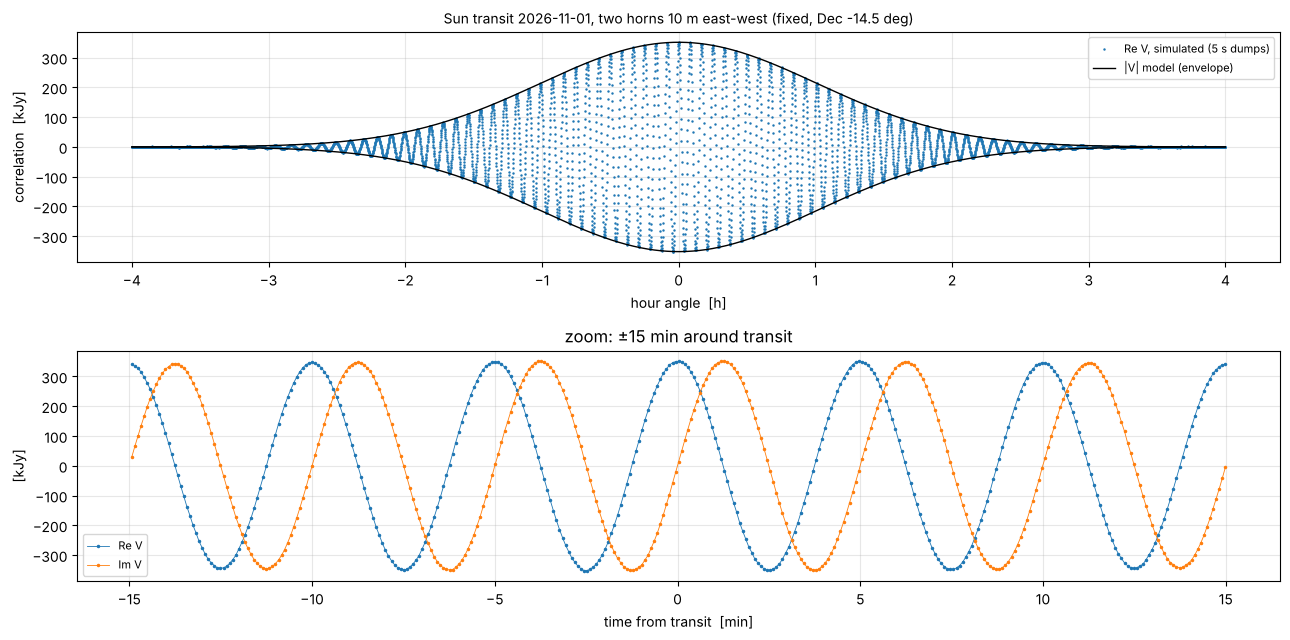

fringe rate at transit 3.34 mHz -> period 5.0 min; peak |V| 352 kJy, noise per dump 767 Jy


In [9]:
horns = Array.from_toml(CFG / "sites" / "two_horns_10m.toml")
ts = TransitSimulator(horns, dec_deg=dec_sun, ha_range_h=(-4, 4), t_dump_s=5.0, date=DATE)
vt = ts.run(sun)
vt0 = TransitSimulator(horns, dec_deg=dec_sun, ha_range_h=(-4, 4), t_dump_s=5.0, add_noise=False, date=DATE).run(sun)
t_h = vt.ha_deg / 15
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
axes[0].plot(t_h, vt.vis[:, 0].real / 1e3, ".", ms=1.5, color="C0", label="Re V, simulated (5 s dumps)")
axes[0].plot(t_h, np.abs(vt0.vis[:, 0]) / 1e3, "k-", lw=1, label="|V| model (envelope)")
axes[0].plot(t_h, -np.abs(vt0.vis[:, 0]) / 1e3, "k-", lw=1)
axes[0].set_xlabel("hour angle  [h]"); axes[0].set_ylabel("correlation  [kJy]"); axes[0].legend(fontsize=8, loc="upper right")
axes[0].set_title(f"Sun transit {DATE}, two horns 10 m east-west (fixed, Dec {dec_sun:+.1f} deg)", fontsize=10)
zoom = np.abs(t_h) < 0.25
axes[1].plot(t_h[zoom] * 60, vt.vis[zoom, 0].real / 1e3, ".-", ms=3, lw=0.6, label="Re V")
axes[1].plot(t_h[zoom] * 60, vt.vis[zoom, 0].imag / 1e3, ".-", ms=3, lw=0.6, label="Im V")
axes[1].set_xlabel("time from transit  [min]")
axes[1].set_ylabel("[kJy]"); axes[1].legend(fontsize=8); axes[1].set_title("zoom: ±15 min around transit")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
o = Observation.from_sky(sun, horns, ha_range_h=(-0.01, 0.01), t_int_s=5, date=DATE)
fr = abs(o.fringe_rate_hz()[0]).max()
print(f"fringe rate at transit {fr * 1e3:.2f} mHz -> period {1 / fr / 60:.1f} min; "
      f"peak |V| {np.abs(vt0.vis).max() / 1e3:.0f} kJy, noise per dump {vt.sigma[len(vt.sigma) // 2, 0]:.0f} Jy")

## 6. Selector

Choose source, array (project baseline, AAS6 stations, two horns, or a free baseline with length and azimuth), hour-angle range, integration time, elevation limit and noise; *Run Interact* shows the elevation, the uv-coverage and the visibilities over the track. (Needs a running kernel.)

In [10]:
import ipywidgets as widgets
from IPython.display import display

SOURCES = dict(SKIES, sun=sun)
ARRAYS = {"project baseline 11.5 km EW": target, "AAS6 stations (11.1 km)": aas6,
          "two horns 10 m": Array.from_toml(CFG / "sites" / "two_horns_10m.toml"),
          "free baseline (below)": None, "hypothetical 3 stations": three}

def run_obs(source, array_name, length_km, azimuth_deg, ha_start_h, ha_end_h, t_int_min, min_elev, noise):
    sky = SOURCES[source]
    arr = ARRAYS[array_name] or baseline_array(length_km * 1e3, azimuth_deg)
    if ha_end_h <= ha_start_h:
        print("hour-angle range is empty"); return
    obs = Observation.from_sky(sky, arr, ha_range_h=(ha_start_h, ha_end_h), t_int_s=t_int_min * 60,
                               min_elev_deg=min_elev, date=DATE)
    cov = UVCoverage.from_observation(obs)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    plot_elevation(obs, ax=axes[0]); plot_uv_coverage(cov, ax=axes[1])
    fig.tight_layout(); plt.show()
    if not obs.visible().any():
        print("source below the elevation limit during the whole range"); return
    vd = VisibilitySimulator(add_noise=noise, seed=1).run(sky, obs)
    mod = VisibilitySimulator(add_noise=False).run(sky, obs)
    plot_visdata(vd, model=mod, figsize=(13, 5)); plt.show()
    print(f"{vd.n_rows} rows; noise sigma per integration {vd.sigma.min():.2f} Jy; "
          f"resolution ~{cov.resolution_arcsec():.3g} arcsec")

display(widgets.interactive(
    run_obs, {"manual": True},
    source=widgets.Dropdown(options=list(SOURCES), value="cyg_a", description="source"),
    array_name=widgets.Dropdown(options=list(ARRAYS), description="array"),
    length_km=widgets.FloatLogSlider(value=1.0, base=10, min=-2, max=1.3, description="length [km]"),
    azimuth_deg=widgets.FloatSlider(value=90, min=0, max=180, step=5, description="azimuth [deg]"),
    ha_start_h=widgets.FloatSlider(value=-6, min=-12, max=12, step=0.5, description="HA start [h]"),
    ha_end_h=widgets.FloatSlider(value=6, min=-12, max=12, step=0.5, description="HA end [h]"),
    t_int_min=widgets.Dropdown(options=[0.5, 1, 2, 5, 10], value=2, description="t_int [min]"),
    min_elev=widgets.FloatSlider(value=10, min=0, max=40, step=1, description="min elev [deg]"),
    noise=widgets.Checkbox(value=True, description="noise"),
))

interactive(children=(Dropdown(description='source', index=1, options=('cas_a', 'cyg_a', 'tau_a', 'vir_a', 'or…